# Question 3.1

In [1]:
import zipfile, os

with zipfile.ZipFile("../data/research_corpus.zip", "r") as z:
    z.extractall("../data")   # creates a research_corpus/ folder

print(sorted(os.listdir("../data/research_corpus")))

['research_1.txt', 'research_2.txt', 'research_3.txt', 'research_4.txt', 'research_5.txt']


In [2]:
import pandas as pd

folder = "../data/research_corpus"
records = []

for i, fname in enumerate(sorted(os.listdir(folder)), start=1):
    if not fname.endswith(".txt"):
        continue
    with open(os.path.join(folder, fname), "r", encoding="utf-8", errors="ignore") as f:
        text = f.read()
    records.append({
        "article_id": i,
        "filename": fname,
        "content": text,
        "word_count": len(text.split())
    })

df = pd.DataFrame(records)
print(df.shape)
display(df[["article_id", "filename", "word_count"]])
print("\nFirst 500 characters of article 1:\n")
print(df.loc[0, "content"][:500])

(5, 4)


,article_id,filename,word_count
0,1,research_1.txt,5602
1,2,research_2.txt,2416
2,3,research_3.txt,3828
3,4,research_4.txt,5922
4,5,research_5.txt,4027



First 500 characters of article 1:

The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative


In [ ]:
pd.set_option("display.max_colwidth", 150)
df.head()

**3.1 Answer:** The corpus was extracted from research_corpus.zip, which contains 5 plain-text research articles. Each file was read into a pandas DataFrame with an article ID, filename, full text content and word count.

# Question 3.2

In [3]:
!pip install spacy nltk -q
!python -m spacy download en_core_web_sm -q

[+] Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [4]:
import re, unicodedata
import nltk, spacy
from collections import Counter

nltk.download("words", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.corpus import words as nltk_words, stopwords

nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Known words = English dictionary + every whole word that appears in the corpus.
corpus_words = set()
for text in df["content"]:
    corpus_words.update(re.findall(r"(?<= )[a-z]+(?= )", text.lower()))
known_words = set(w.lower() for w in nltk_words.words()) | corpus_words


def fix_line_breaks(text):
    """Re-join words split across lines (e.g. 'pragma\\ntism' -> 'pragmatism')."""
    def join_hyphen(m):
        a, b = m.group(1), m.group(2)
        if (a + b).lower() in known_words:
            return a + b                    # 're-\nsearch' -> 'research'
        return a + "-" + b                  # 'mixed-\nmethods' -> 'mixed-methods'
    text = re.sub(r"([A-Za-z]+)-\n([A-Za-z]+)", join_hyphen, text)

    def join(m):
        a, b = m.group(1).lower(), m.group(2).lower()
        if (a + b) in known_words or (a not in known_words and b not in known_words):
            return m.group(1)
        return m.group(1) + " "
    return re.sub(r"([A-Za-z]+)\n(?=([a-z]+))", join, text)


def remove_references(text):
    """Cut off the reference list if there is one near the end."""
    matches = list(re.finditer(r"\n\s*(references|bibliography|works cited)\s*\n", text, re.I))
    if matches and matches[-1].start() > len(text) * 0.5:
        return text[:matches[-1].start()]
    return text


def light_clean(text):
    """Denoise but keep sentences intact (used for summarisation in 3.3)."""
    text = unicodedata.normalize("NFKD", text)
    text = text.replace("“", '"').replace("”", '"').replace("’", "'").replace("‘", "'")
    text = remove_references(text)
    text = fix_line_breaks(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)              # URLs
    text = re.sub(r"\S+@\S+", " ", text)                            # emails
    text = re.sub(r"\bdoi:?\s*\S+", " ", text, flags=re.I)          # DOIs
    text = re.sub(r"\[[\d,\s\-–]+\]", " ", text)                     # [12], [3-5]
    text = re.sub(r"(?<=[a-z])\.\d{1,2}(?=\s+[A-Z])", ".", text)      # footnotes: 'research.5 We'
    text = re.sub(r"\([^()]*\b(19|20)\d{2}[a-z]?\b[^()]*\)", " ", text)  # (Smith, 2004)
    text = re.sub(r"[^\x00-\x7F]+", " ", text)                       # leftover non-ASCII
    text = re.sub(r"\s+", " ", text)                                 # collapse whitespace
    return text.strip()


stop_words = set(stopwords.words("english")) | {"et", "al", "also", "however", "thus", "may", "one", "use", "used"}

def deep_clean(text):
    """Full normalisation for topic modelling (3.4): lowercase, letters only, lemmatise, drop stopwords."""
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    doc = nlp(text)
    tokens = [t.lemma_ for t in doc
              if t.lemma_ not in stop_words and len(t.lemma_) > 2 and t.is_alpha]
    return " ".join(tokens)


df["clean_text"] = df["content"].apply(light_clean)
df["processed_text"] = df["clean_text"].apply(deep_clean)
df["clean_word_count"] = df["processed_text"].apply(lambda x: len(x.split()))

display(df[["article_id", "filename", "word_count", "clean_word_count"]])
print("\nArticle 1, light clean (first 500 chars):\n", df.loc[0, "clean_text"][:500])
print("\nArticle 1, fully processed (first 300 chars):\n", df.loc[0, "processed_text"][:300])
print("\nTop 15 words across the corpus after cleaning:\n",
      Counter(" ".join(df["processed_text"]).split()).most_common(15))

,article_id,filename,word_count,clean_word_count
0,1,research_1.txt,5602,2946
1,2,research_2.txt,2416,1162
2,3,research_3.txt,3828,2054
3,4,research_4.txt,5922,3075
4,5,research_5.txt,4027,2057



Article 1, light clean (first 500 chars):
 The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research. In this, we briefly review the paradigm "wars" and incompatibility thesis, we show some commonalities between quantitative and qualitative resea

Article 1, fully processed (first 300 chars):
 purpose article position mixed method research mixed research synonym natural complement traditional qualitative quantitative research present pragmatism offer attractive philosophical partner mixed method research provide framework design conduct mixed method research briefly review paradigm war in

Top 15 words across the corpus after cleaning:
 [('research', 399), ('study', 160), ('researcher', 150), 

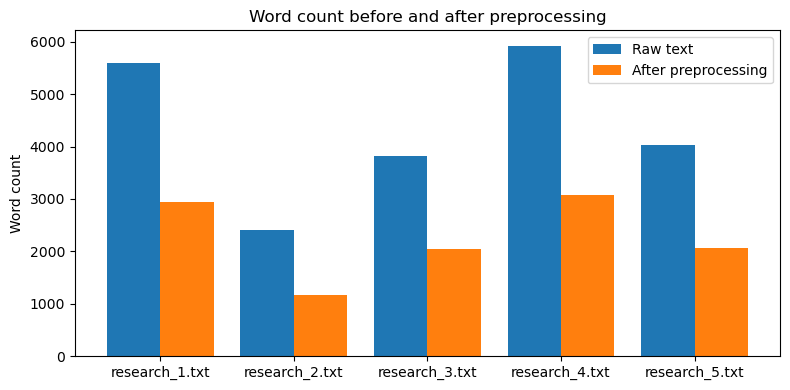

Overall noise reduction: 48.2%


In [5]:
import matplotlib.pyplot as plt

# Fix spaCy lemmatising "data" -> "datum"
df["processed_text"] = df["processed_text"].str.replace(r"\bdatum\b", "data", regex=True)
df["clean_word_count"] = df["processed_text"].apply(lambda x: len(x.split()))

# Visualise the effect of preprocessing
x = range(len(df))
plt.figure(figsize=(8, 4))
plt.bar([i - 0.2 for i in x], df["word_count"], width=0.4, label="Raw text")
plt.bar([i + 0.2 for i in x], df["clean_word_count"], width=0.4, label="After preprocessing")
plt.xticks(x, df["filename"])
plt.ylabel("Word count")
plt.title("Word count before and after preprocessing")
plt.legend()
plt.tight_layout()
plt.show()

reduction = (1 - df["clean_word_count"].sum() / df["word_count"].sum()) * 100
print(f"Overall noise reduction: {reduction:.1f}%")

**3.2 Answer – denoising techniques applied:**

Each article went through a denoising pipeline using spaCy (Honnibal et al., 2020) and NLTK (Bird, Klein and Loper, 2009):

- **Line-break repair:** words split across lines when the text was extracted from PDF (e.g. "pragma / tism") were re-joined using an English dictionary plus the corpus vocabulary
- **Reference lists, URLs, emails, DOIs, in-text citations and footnote numbers** were removed
- **Unicode normalisation** and removal of leftover non-ASCII characters
- **Lowercasing, stopword removal and lemmatisation** (e.g. "studies" → "study"); spaCy's "datum" lemma was mapped back to "data"

Two versions were kept: `clean_text`, which keeps full sentences for extractive summarisation (3.3), and `processed_text`, which is fully normalised for topic modelling (3.4 and 4.1).

**Result:** Preprocessing reduced the corpus by 48.2%, from 21,795 to 11,294 words. It removed stopwords, citations, punctuation and formatting noise, and kept the meaningful content words.

# Question 3.3

In [6]:
!pip install wordcloud networkx scikit-learn -q

In [8]:
import networkx as nx
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

article1 = df.loc[0, "clean_text"]

# 1. Split into sentences and drop very short fragments
sentences = re.split(r"(?<=[.!?])\s+(?=[A-Z])", article1)
sentences = [s.strip() for s in sentences if len(s.split()) >= 8]

# 2. Remove duplicate sentences (the source text repeats some passages)
seen, unique = set(), []
for s in sentences:
    key = re.sub(r"\W+", "", s.lower())
    if key not in seen:
        seen.add(key)
        unique.append(s)
print(f"Article 1: {len(sentences)} sentences, {len(sentences) - len(unique)} duplicates removed, {len(unique)} kept")
sentences = unique

# 3. Clean each sentence the same way as 3.2, then turn it into a TF-IDF vector
clean_sents = [deep_clean(s).replace("datum", "data") for s in sentences]
tfidf = TfidfVectorizer().fit_transform(clean_sents)

# 4. Build a similarity graph and score sentences with PageRank
sim_matrix = cosine_similarity(tfidf)
np.fill_diagonal(sim_matrix, 0)
graph = nx.from_numpy_array(sim_matrix)
scores = nx.pagerank(graph)

# 5. Take the top 7 sentences and put them back in their original order
top_n = 7
top_idx = sorted(sorted(scores, key=scores.get, reverse=True)[:top_n])
summary = " ".join(sentences[i] for i in top_idx)

print(f"\nSUMMARY OF ARTICLE 1 ({len(summary.split())} words, down from {df.loc[0, 'word_count']}):\n")
for i in top_idx:
    print(f"• {sentences[i]}\n")

Article 1: 150 sentences, 75 duplicates removed, 75 kept

SUMMARY OF ARTICLE 1 (255 words, down from 5602):

• The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

• In this, we briefly review the paradigm "wars" and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the tenets of pragmatism, we explain the fundamental principle of mixed research and how to apply it, we provide specific sets of designs for the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process.

• Both sets of purists view their p

**3.3 Answer – summary of article 1 (TextRank):**

Article 1 was summarised with **TextRank** (Mihalcea and Tarau, 2004), an extractive, graph-based method. The cleaned article was split into sentences and each sentence was turned into a TF-IDF vector (Pedregosa et al., 2011). Cosine similarity between every pair of sentences was used to build a graph, and PageRank (Page et al., 1999) scored each sentence by how central it is to the rest of the text. The 7 highest-scoring sentences, kept in their original order, form the summary, which reduces the article from 5,602 words to about 255.

While checking the output, 75 of the 150 sentences turned out to be exact duplicates: the article text appears twice in the source file. Duplicates were removed before ranking, because identical sentences are 100% similar to each other and would otherwise push one another to the top.

The summary shows that the article (Johnson and Onwuegbuzie, 2004) presents **mixed methods research as a "third research paradigm"** alongside qualitative and quantitative research. It proposes **pragmatism** as its philosophical basis, rejects the "incompatibility thesis" held by purists on both sides, and offers a framework for designing mixed methods studies.

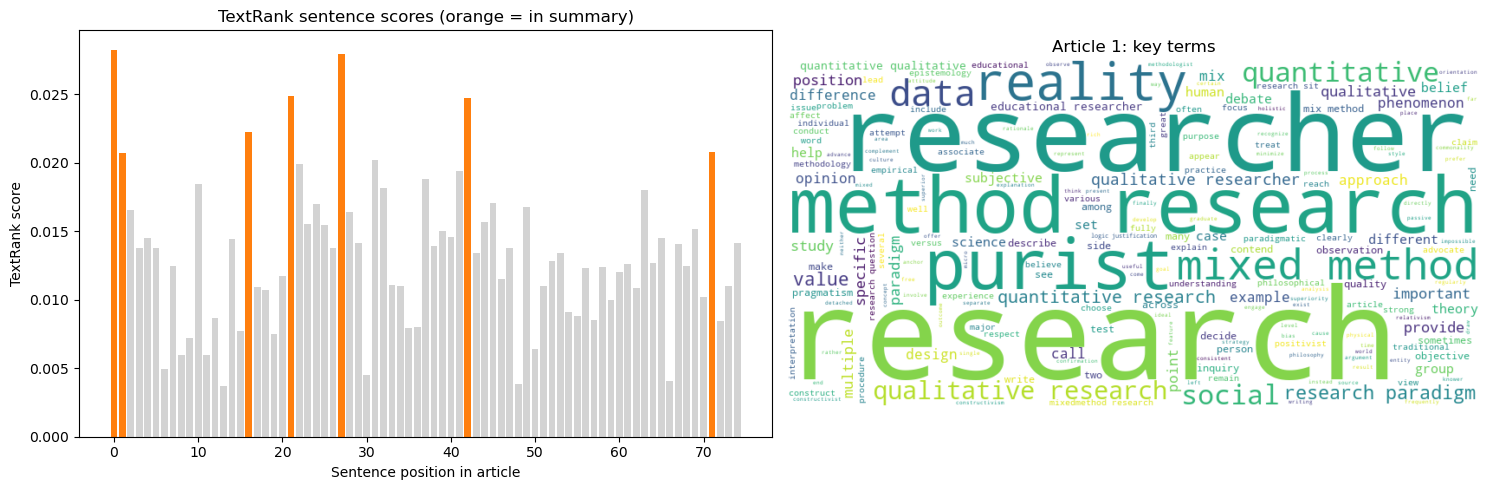

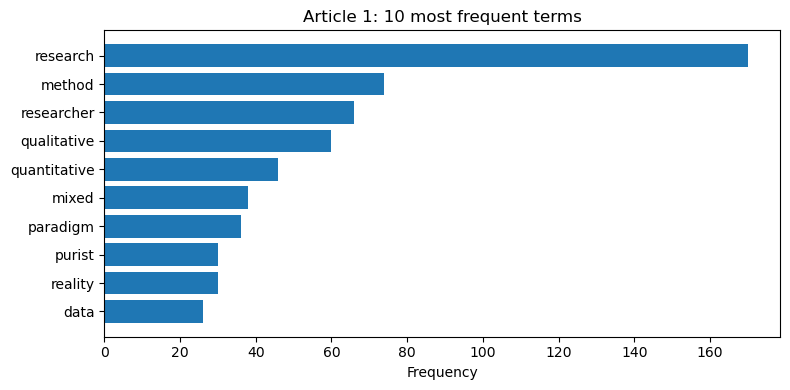

In [9]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Sentence importance scores: summary sentences highlighted
score_list = [scores[i] for i in range(len(sentences))]
colors = ["tab:orange" if i in top_idx else "lightgrey" for i in range(len(sentences))]
axes[0].bar(range(len(sentences)), score_list, color=colors)
axes[0].set_xlabel("Sentence position in article")
axes[0].set_ylabel("TextRank score")
axes[0].set_title("TextRank sentence scores (orange = in summary)")

# (b) Word cloud of article 1
wc = WordCloud(width=800, height=400, background_color="white",
               colormap="viridis").generate(df.loc[0, "processed_text"])
axes[1].imshow(wc, interpolation="bilinear")
axes[1].axis("off")
axes[1].set_title("Article 1: key terms")

plt.tight_layout()
plt.show()

# (c) Top 10 terms in article 1
top_terms = Counter(df.loc[0, "processed_text"].split()).most_common(10)
plt.figure(figsize=(8, 4))
plt.barh([w for w, c in top_terms][::-1], [c for w, c in top_terms][::-1], color="tab:blue")
plt.title("Article 1: 10 most frequent terms")
plt.xlabel("Frequency")
plt.tight_layout()
plt.show()

**3.3 Answer – visualisations:** The TextRank score chart shows that most of the top-ranked sentences come from the opening section of the article, where the authors state their aims and argument. The word cloud and frequency chart confirm the article’s focus on mixed methods research, qualitative versus quantitative paradigms, and the debate between “purists” on each side.

# Question 3.4

In [10]:
def dedupe_sentences(text):
    """Remove repeated sentences from an article, keeping the first occurrence."""
    sents = re.split(r"(?<=[.!?])\s+(?=[A-Z])", text)
    seen, kept = set(), []
    for s in sents:
        key = re.sub(r"\W+", "", s.lower())
        if key and key not in seen:
            seen.add(key)
            kept.append(s.strip())
    return " ".join(kept), len(sents) - len(kept), len(sents)

results = df["clean_text"].apply(dedupe_sentences)
df["clean_text"] = results.apply(lambda r: r[0])
df["duplicates_removed"] = results.apply(lambda r: r[1])
df["total_sentences"] = results.apply(lambda r: r[2])

# Re-process the de-duplicated text
df["processed_text"] = df["clean_text"].apply(deep_clean).str.replace(r"\bdatum\b", "data", regex=True)
df["clean_word_count"] = df["processed_text"].apply(lambda x: len(x.split()))

display(df[["article_id", "filename", "total_sentences", "duplicates_removed", "clean_word_count"]])


,article_id,filename,total_sentences,duplicates_removed,clean_word_count
0,1,research_1.txt,152,76,1473
1,2,research_2.txt,57,0,1162
2,3,research_3.txt,150,0,2054
3,4,research_4.txt,176,0,3075
4,5,research_5.txt,161,0,2057


**Approach:** 3.3 used TextRank, which picks the most important sentences from one article. For 3.4 the question asks for a different technique that summarises the whole group at once, so I used **LDA topic modelling** (Blei, Ng and Jordan, 2003). It finds the main themes across the four articles and the key words that define each theme.

LDA needs many documents to learn from, and four articles are too few. So each article is split into chunks of about five sentences, and every chunk is treated as a small document.

In [11]:
!pip install gensim -q

110 text chunks created from 4 articles
research_2.txt    12
research_3.txt    30
research_4.txt    35
research_5.txt    33
Name: count, dtype: int64

Vocabulary size after filtering: 928
k = 2: coherence = 0.4239
k = 3: coherence = 0.4763
k = 4: coherence = 0.6551
k = 5: coherence = 0.6691
k = 6: coherence = 0.6346
k = 7: coherence = 0.6777
k = 8: coherence = 0.6351


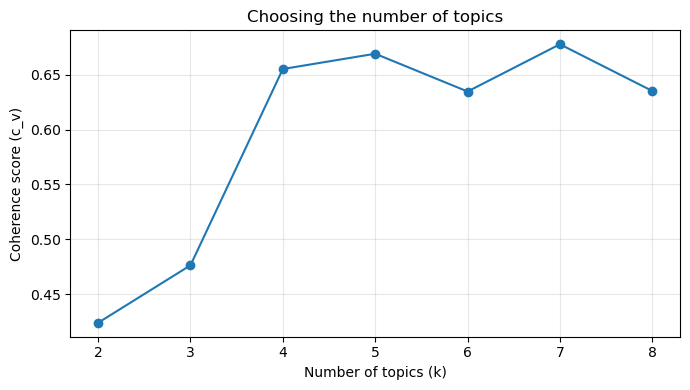

In [12]:
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

# Articles 2–5 only
rest = df[df["article_id"] > 1].reset_index(drop=True)

# Split each article into chunks of 5 sentences; each chunk is one "document" for LDA
chunk_size = 5
docs, doc_article = [], []
for _, row in rest.iterrows():
    sents = re.split(r"(?<=[.!?])\s+(?=[A-Z])", row["clean_text"])
    for i in range(0, len(sents), chunk_size):
        tokens = deep_clean(" ".join(sents[i:i + chunk_size])).replace("datum", "data").split()
        if len(tokens) >= 10:
            docs.append(tokens)
            doc_article.append(row["filename"])

print(f"{len(docs)} text chunks created from {len(rest)} articles")
print(pd.Series(doc_article).value_counts().sort_index())

# Build the dictionary and bag-of-words corpus
dictionary = corpora.Dictionary(docs)
dictionary.filter_extremes(no_below=2, no_above=0.5)   # drop very rare and very common words
corpus = [dictionary.doc2bow(d) for d in docs]
print(f"\nVocabulary size after filtering: {len(dictionary)}")

# Try 2 to 8 topics and measure coherence (higher = more interpretable topics)
coherence_scores = {}
for k in range(2, 9):
    model = LdaModel(corpus=corpus, id2word=dictionary, num_topics=k,
                     random_state=42, passes=15, alpha="auto")
    cm = CoherenceModel(model=model, texts=docs, dictionary=dictionary,
                        coherence="c_v", processes=1)
    coherence_scores[k] = cm.get_coherence()
    print(f"k = {k}: coherence = {coherence_scores[k]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(list(coherence_scores.keys()), list(coherence_scores.values()), marker="o")
plt.xlabel("Number of topics (k)")
plt.ylabel("Coherence score (c_v)")
plt.title("Choosing the number of topics")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
best_k = 5
lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=best_k,
               random_state=42, passes=15, alpha="auto")

final_cm = CoherenceModel(model=lda, texts=docs, dictionary=dictionary,
                          coherence="c_v", processes=1)
print(f"Final model coherence: {final_cm.get_coherence():.4f}\n")

for t in range(best_k):
    words = ", ".join(w for w, p in lda.show_topic(t, topn=10))
    print(f"Topic {t+1}: {words}")

Final model coherence: 0.6691

Topic 1: knowledge, instrument, alpha, science, report, scale, measure, cronbach, item, education
Topic 2: researcher, experience, reflexivity, qualitative, position, share, personal, social, change, address
Topic 3: data, triangulation, method, design, researcher, qualitative, multiple, denzin, student, case
Topic 4: development, design, developmental, process, instructional, evaluation, type, product, field, term
Topic 5: alpha, value, cronbach, reliability, internal, consistency, report, statistic, paper, science


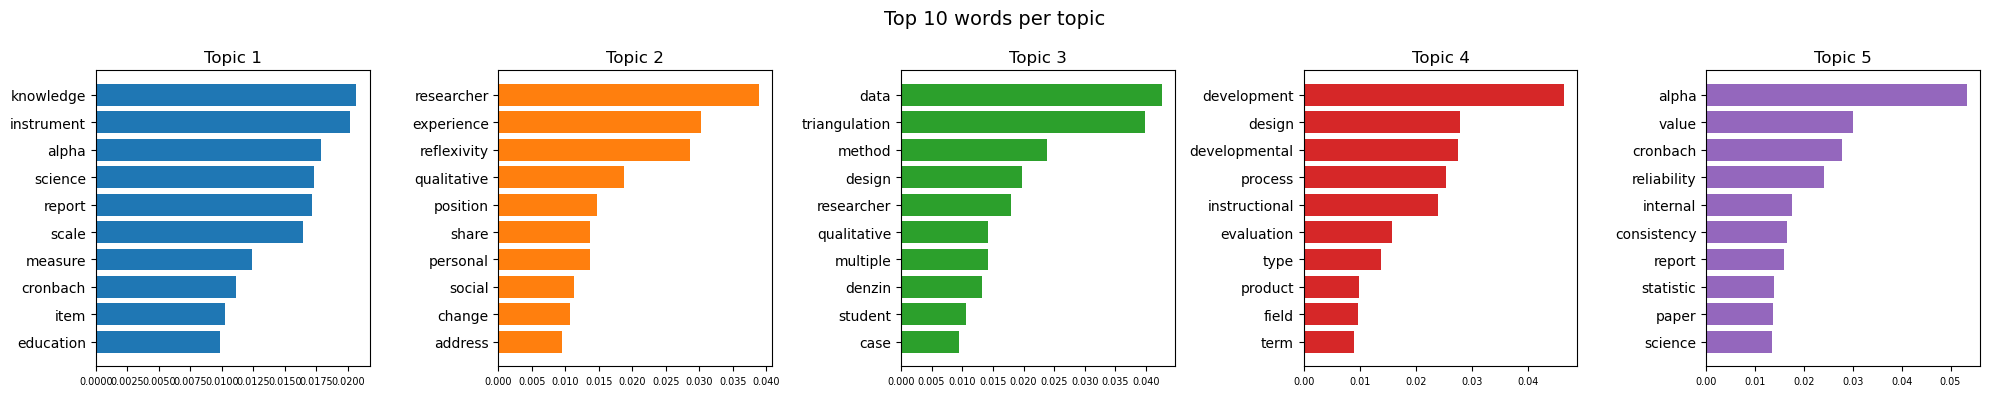

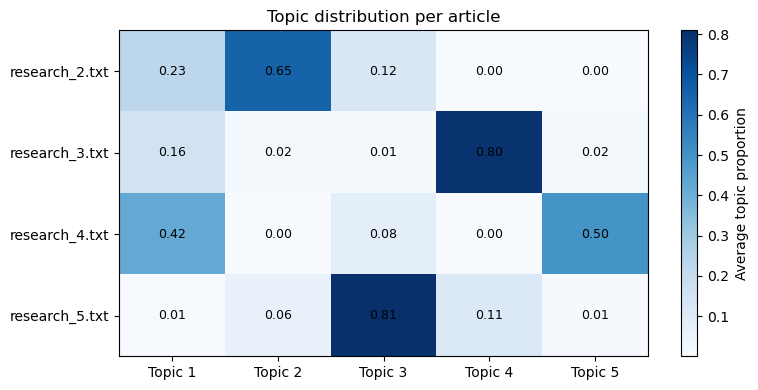

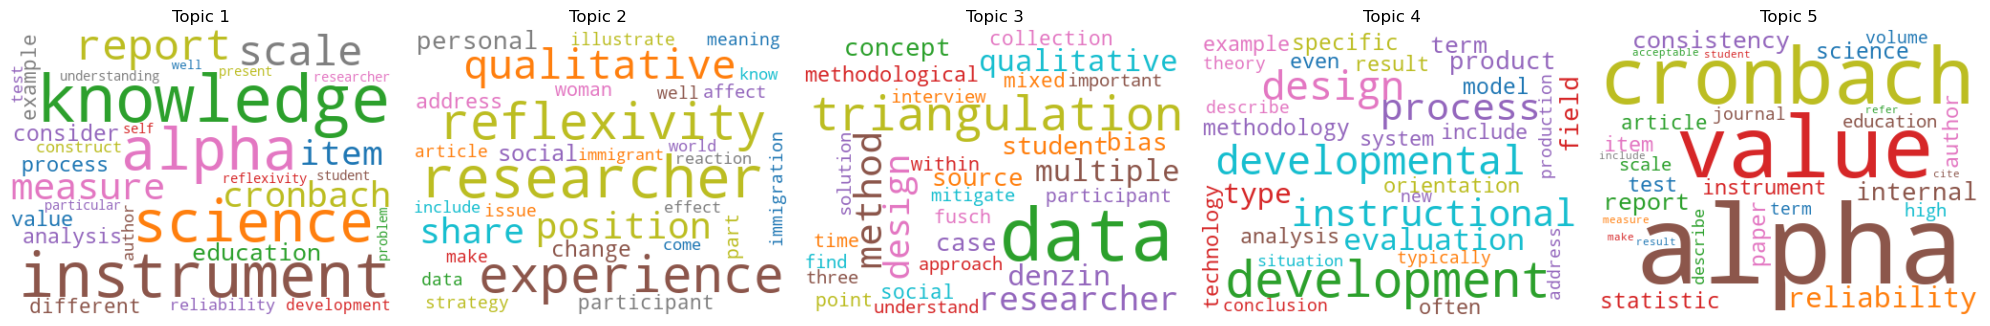

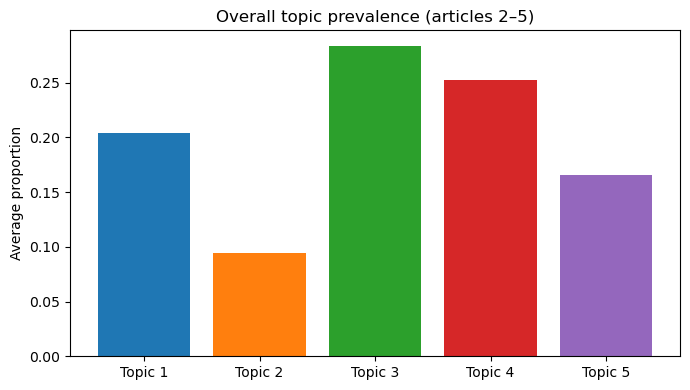

In [14]:
# Topic mix for every chunk, then averaged per article
doc_topics = np.zeros((len(corpus), best_k))
for i, bow in enumerate(corpus):
    for t, p in lda.get_document_topics(bow, minimum_probability=0):
        doc_topics[i, t] = p
topic_cols = [f"Topic {t+1}" for t in range(best_k)]
dt_df = pd.DataFrame(doc_topics, columns=topic_cols)
dt_df["article"] = doc_article
article_topics = dt_df.groupby("article")[topic_cols].mean()

# (a) Top 10 words per topic
fig, axes = plt.subplots(1, best_k, figsize=(4 * best_k, 4))
for t in range(best_k):
    words, probs = zip(*lda.show_topic(t, topn=10))
    axes[t].barh(words[::-1], probs[::-1], color=f"C{t}")
    axes[t].set_title(f"Topic {t+1}")
    axes[t].tick_params(axis="x", labelsize=7)
fig.suptitle("Top 10 words per topic", fontsize=14)
plt.tight_layout()
plt.show()

# (b) Heatmap: how much each article is about each topic
plt.figure(figsize=(8, 4))
plt.imshow(article_topics.values, cmap="Blues", aspect="auto")
plt.colorbar(label="Average topic proportion")
plt.xticks(range(best_k), topic_cols)
plt.yticks(range(len(article_topics)), article_topics.index)
for i in range(article_topics.shape[0]):
    for j in range(best_k):
        plt.text(j, i, f"{article_topics.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.title("Topic distribution per article")
plt.tight_layout()
plt.show()

# (c) Word cloud per topic
fig, axes = plt.subplots(1, best_k, figsize=(4 * best_k, 3.5))
for t in range(best_k):
    wc = WordCloud(width=400, height=300, background_color="white", colormap="tab10") \
         .generate_from_frequencies(dict(lda.show_topic(t, topn=30)))
    axes[t].imshow(wc, interpolation="bilinear")
    axes[t].axis("off")
    axes[t].set_title(f"Topic {t+1}")
plt.tight_layout()
plt.show()

# (d) Overall share of each topic across the whole corpus
plt.figure(figsize=(7, 4))
plt.bar(topic_cols, dt_df[topic_cols].mean(), color=[f"C{t}" for t in range(best_k)])
plt.ylabel("Average proportion")
plt.title("Overall topic prevalence (articles 2–5)")
plt.tight_layout()
plt.show()

**3.4 Answer – aggregate summary of articles 2–5:**

For the remaining four articles I used **LDA topic modelling** (Blei, Ng and Jordan, 2003). Instead of picking out sentences like TextRank did in 3.3, LDA looks at which words tend to appear together and groups them into topics. That makes it a good way to summarise several articles at once.

Four articles aren't enough for LDA on their own, so I split each one into chunks of five sentences, which gave 110 small documents. I tested between 2 and 8 topics and picked **5**. Its c_v coherence score (0.669) (Röder, Both and Hinneburg, 2015) was almost as high as the best one (0.678 at 7 topics), and 5 topics are easier to make sense of.

**The 5 topics:**

1. **Measurement tools in science education**: instruments, scales, items
2. **Reflexivity**: how a researcher's own background and position affect their research
3. **Triangulation**: using several data sources or methods to check findings
4. **Developmental research**: designing and testing instructional products
5. **Reliability**: using and reporting Cronbach's alpha

**What the articles are about:** The heatmap shows that each article focuses mainly on one topic. Article 2 is about reflexivity, Article 3 about developmental research, Article 4 about measurement tools and Cronbach's alpha, and Article 5 about triangulation. Put together, all four articles deal with the same big question: **how to make research trustworthy**. Each one covers a different way of doing that, which fits well with Article 1's argument for mixed methods research.

**Limitations:** Topics 1 and 5 overlap a bit because both come from Article 4. With only four articles, the topics mostly line up with one article each instead of spreading across all of them.

**Note:** The brief describes the corpus as AI research articles, but the topic modelling shows the articles are about research methodology and research quality, not AI. This shows how topic modelling can reveal what a collection is really about, regardless of how it was labelled.

# Question 4.1

126 chunks from 5 articles

Bigrams detected (63): ['acceptable_value', 'alpha_statistic', 'alpha_value', 'author_report', 'blend_design', 'case_study', 'conceptual_framework', 'construct_validity', 'context_specific', 'cronbach_alpha', 'data_collect', 'data_collection', 'data_saturation', 'data_triangulation', 'design_development', 'development_evaluation', 'development_process', 'developmental_research', 'diagnostic_instrument', 'educational_researcher', 'evaluation_process', 'even_though', 'explicit_reference', 'factor_analysis', 'four_type']

Vocabulary size: 1119
k = 2: coherence = 0.4507
k = 3: coherence = 0.5316
k = 4: coherence = 0.4526
k = 5: coherence = 0.4314
k = 6: coherence = 0.4497
k = 7: coherence = 0.4508
k = 8: coherence = 0.3726
k = 9: coherence = 0.3881
k = 10: coherence = 0.3921


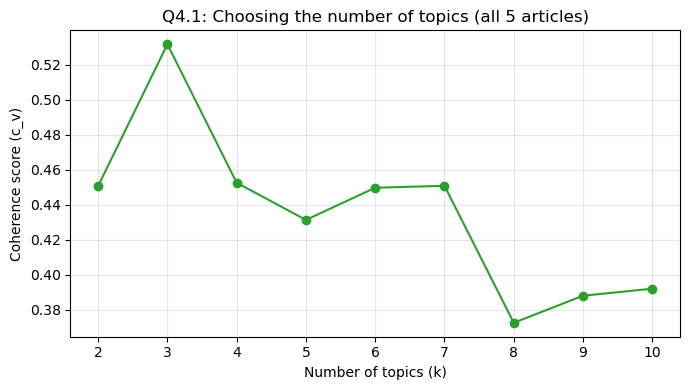

In [16]:
from gensim.models.phrases import Phrases, Phraser

# Split all 5 articles into 5-sentence chunks (each chunk = one document for LDA)
docs_all, doc_article_all = [], []
for _, row in df.iterrows():
    sents = re.split(r"(?<=[.!?])\s+(?=[A-Z])", row["clean_text"])
    for i in range(0, len(sents), 5):
        tokens = deep_clean(" ".join(sents[i:i + 5])).replace("datum", "data").split()
        if len(tokens) >= 10:
            docs_all.append(tokens)
            doc_article_all.append(row["filename"])

# Detect common two-word phrases (bigrams), e.g. "mixed method" -> "mixed_method"
bigram = Phraser(Phrases(docs_all, min_count=3, threshold=10))
docs_all = [bigram[d] for d in docs_all]
found_bigrams = sorted({w for d in docs_all for w in d if "_" in w})
print(f"{len(docs_all)} chunks from {df.shape[0]} articles")
print(f"\nBigrams detected ({len(found_bigrams)}):", found_bigrams[:25])

# Dictionary and corpus
dictionary_all = corpora.Dictionary(docs_all)
dictionary_all.filter_extremes(no_below=2, no_above=0.5)
corpus_all = [dictionary_all.doc2bow(d) for d in docs_all]
print(f"\nVocabulary size: {len(dictionary_all)}")

# Test 2–10 topics
coherence_all = {}
for k in range(2, 11):
    m = LdaModel(corpus=corpus_all, id2word=dictionary_all, num_topics=k,
                 random_state=42, passes=15, alpha="auto")
    coherence_all[k] = CoherenceModel(model=m, texts=docs_all, dictionary=dictionary_all,
                                      coherence="c_v", processes=1).get_coherence()
    print(f"k = {k}: coherence = {coherence_all[k]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(list(coherence_all.keys()), list(coherence_all.values()), marker="o", color="tab:green")
plt.xlabel("Number of topics (k)")
plt.ylabel("Coherence score (c_v)")
plt.title("Q4.1: Choosing the number of topics (all 5 articles)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
for k in [3, 5]:
    m = LdaModel(corpus=corpus_all, id2word=dictionary_all, num_topics=k,
                 random_state=42, passes=15, alpha="auto")
    print(f"===== k = {k}  (coherence {coherence_all[k]:.4f}) =====")
    for t in range(k):
        print(f"Topic {t+1}: " + ", ".join(w for w, p in m.show_topic(t, topn=10)))
    print()

===== k = 3  (coherence 0.5316) =====
Topic 1: researcher, data, triangulation, method, design, denzin, mixed_method, qualitative_research, example, multiple
Topic 2: process, alpha, report, development, knowledge, reflexivity, cronbach_alpha, value, scale, reliability
Topic 3: instrument, scale, item, measure, cronbach_alpha, report, reliability, development, test, consider

===== k = 5  (coherence 0.4314) =====
Topic 1: data, design, field, triangulation, case_study, point, researcher, development, process, student
Topic 2: alpha, reflexivity, knowledge, report, scale, process, cronbach_alpha, researcher, item, article
Topic 3: instrument, test, cronbach_alpha, measure, item, report, scale, reliability, science_education, consider
Topic 4: method, triangulation, denzin, mixed_method, researcher, data, data_triangulation, multiple, paradigm, design
Topic 5: researcher, design, analysis, evaluation, developmental_research, development, reality, process, example, important



**Choice of k:** k = 3 had the highest coherence (0.53), but it merged unrelated themes into one topic. k = 5 was chosen because it gave more distinct, interpretable topics and fits the 5-article corpus better.

TOPIC–WORD DISTRIBUTION (top 10 words and their weights)

Topic 1: 0.024*data + 0.015*design + 0.012*field + 0.011*triangulation + 0.010*case_study + 0.010*point + 0.010*researcher + 0.009*development + 0.009*process + 0.009*student
Topic 2: 0.015*alpha + 0.013*reflexivity + 0.013*knowledge + 0.012*report + 0.010*scale + 0.010*process + 0.010*cronbach_alpha + 0.009*researcher + 0.008*item + 0.008*article
Topic 3: 0.027*instrument + 0.018*test + 0.016*cronbach_alpha + 0.014*measure + 0.014*item + 0.014*report + 0.013*scale + 0.013*reliability + 0.012*science_education + 0.011*consider
Topic 4: 0.024*method + 0.023*triangulation + 0.016*denzin + 0.014*mixed_method + 0.014*researcher + 0.014*data + 0.012*data_triangulation + 0.011*multiple + 0.011*paradigm + 0.009*design
Topic 5: 0.017*researcher + 0.012*design + 0.009*analysis + 0.009*evaluation + 0.007*developmental_research + 0.007*development + 0.007*reality + 0.007*process + 0.006*example + 0.006*important

DOCUMENT–TOPIC DISTRIBUTIO

,Topic 1,Topic 2,Topic 3,Topic 4,Topic 5
article,,,,,
research_1.txt,0.00,0.03,0.04,0.35,0.58
research_2.txt,0.10,0.43,0.00,0.17,0.30
research_3.txt,0.15,0.32,0.05,0.00,0.47
research_4.txt,0.06,0.47,0.46,0.00,0.01
research_5.txt,0.25,0.00,0.02,0.45,0.27


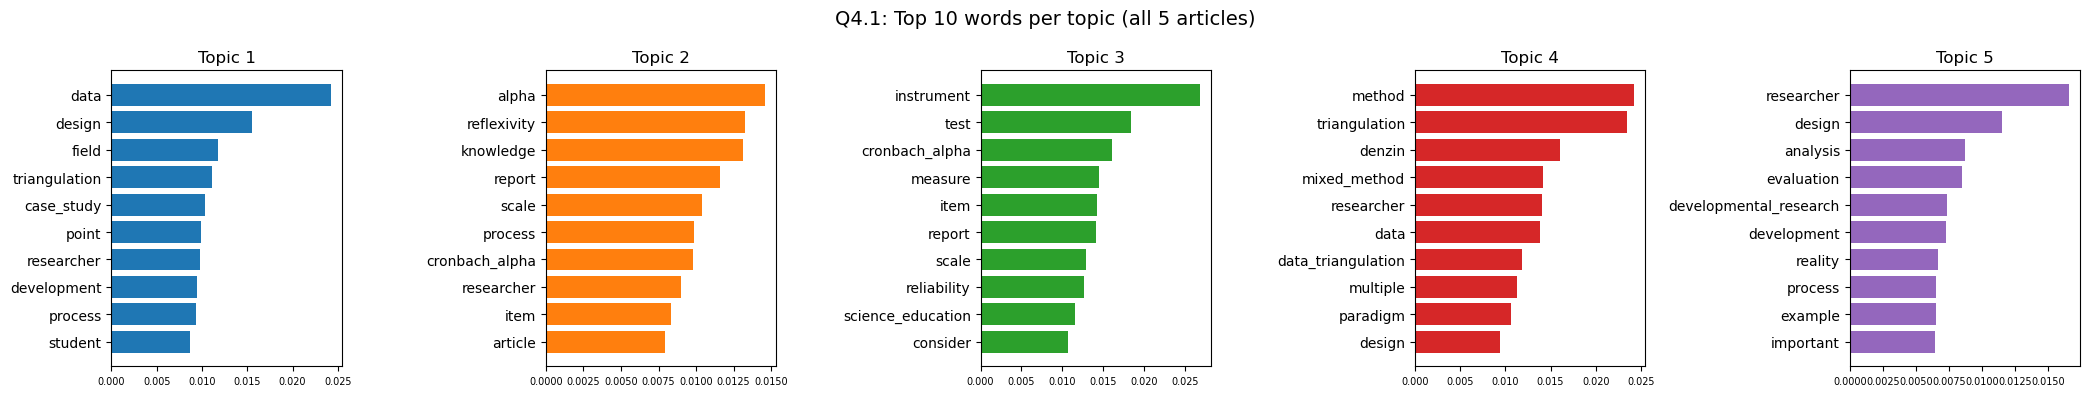

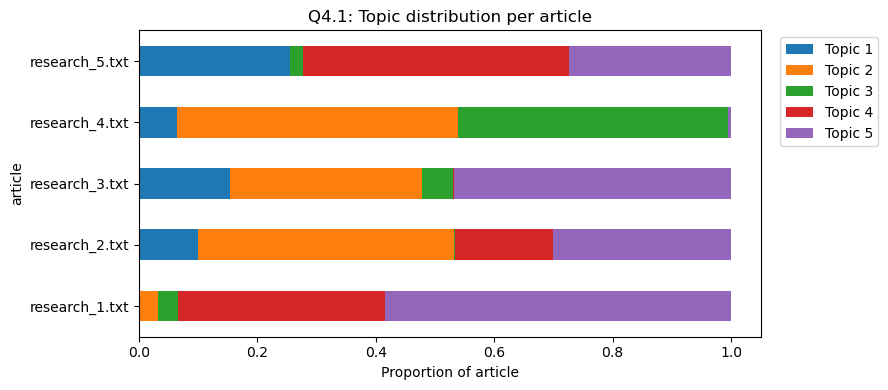

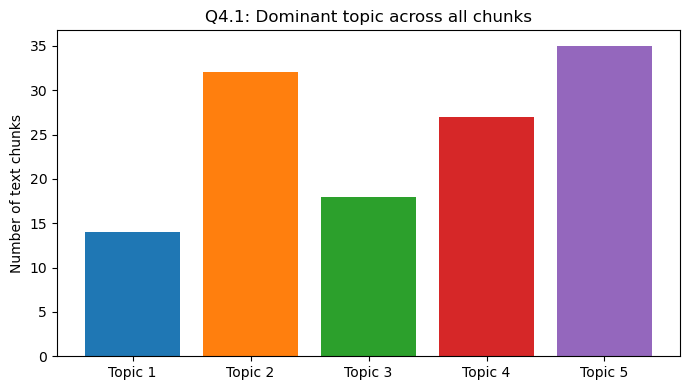

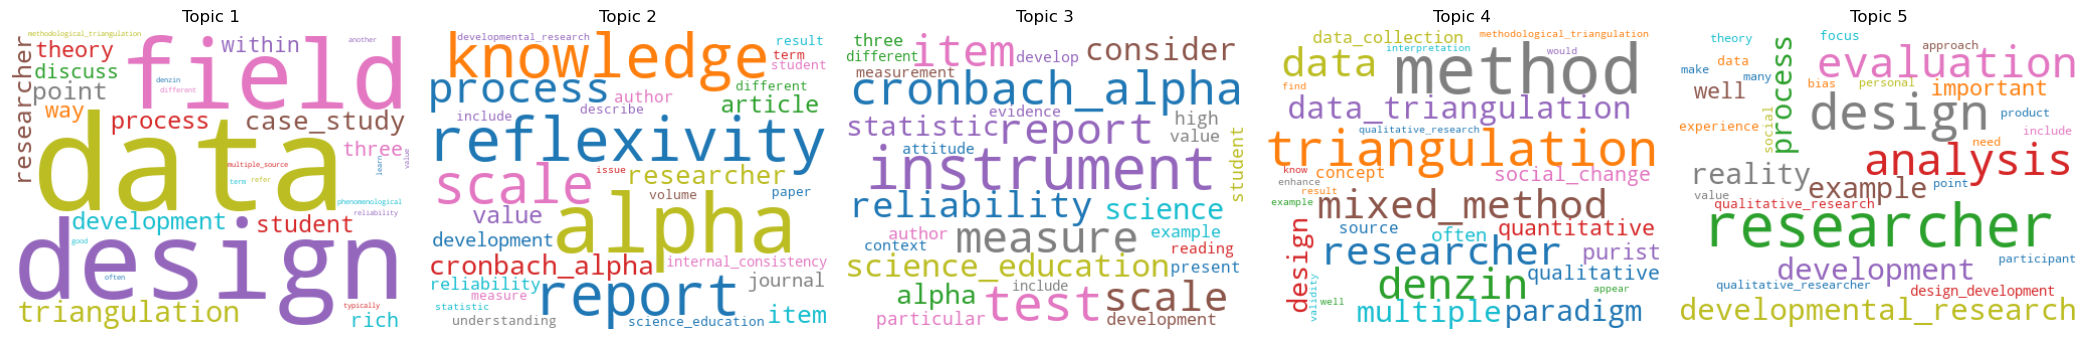

In [19]:
best_k_all = 5
lda_all = LdaModel(corpus=corpus_all, id2word=dictionary_all, num_topics=best_k_all,
                   random_state=42, passes=15, alpha="auto")
topic_cols_all = [f"Topic {t+1}" for t in range(best_k_all)]

# ---- Topic word lists with their probabilities (topic–word distribution) ----
print("TOPIC–WORD DISTRIBUTION (top 10 words and their weights)\n")
for t in range(best_k_all):
    print(f"Topic {t+1}: " + " + ".join(f"{p:.3f}*{w}" for w, p in lda_all.show_topic(t, topn=10)))

# ---- Topic distribution per chunk and per article (document–topic distribution) ----
dt_all = np.zeros((len(corpus_all), best_k_all))
for i, bow in enumerate(corpus_all):
    for t, p in lda_all.get_document_topics(bow, minimum_probability=0):
        dt_all[i, t] = p
dt_all_df = pd.DataFrame(dt_all, columns=topic_cols_all)
dt_all_df["article"] = doc_article_all
dt_all_df["dominant_topic"] = dt_all_df[topic_cols_all].idxmax(axis=1)
article_mix = dt_all_df.groupby("article")[topic_cols_all].mean()

print("\nDOCUMENT–TOPIC DISTRIBUTION (average per article)\n")
display(article_mix.round(2))

# (a) Top 10 words per topic
fig, axes = plt.subplots(1, best_k_all, figsize=(4.2 * best_k_all, 4))
for t in range(best_k_all):
    words, probs = zip(*lda_all.show_topic(t, topn=10))
    axes[t].barh(words[::-1], probs[::-1], color=f"C{t}")
    axes[t].set_title(f"Topic {t+1}")
    axes[t].tick_params(axis="x", labelsize=7)
fig.suptitle("Q4.1: Top 10 words per topic (all 5 articles)", fontsize=14)
plt.tight_layout()
plt.show()

# (b) Stacked bar: topic mix in each article
article_mix.plot(kind="barh", stacked=True, figsize=(9, 4), color=[f"C{t}" for t in range(best_k_all)])
plt.xlabel("Proportion of article")
plt.title("Q4.1: Topic distribution per article")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# (c) Overall topic distribution: how many chunks each topic dominates
counts = dt_all_df["dominant_topic"].value_counts().reindex(topic_cols_all, fill_value=0)
plt.figure(figsize=(7, 4))
plt.bar(counts.index, counts.values, color=[f"C{t}" for t in range(best_k_all)])
plt.ylabel("Number of text chunks")
plt.title("Q4.1: Dominant topic across all chunks")
plt.tight_layout()
plt.show()

# (d) Word clouds per topic
fig, axes = plt.subplots(1, best_k_all, figsize=(4.2 * best_k_all, 3.5))
for t in range(best_k_all):
    wc = WordCloud(width=400, height=300, background_color="white", colormap="tab10") \
         .generate_from_frequencies(dict(lda_all.show_topic(t, topn=30)))
    axes[t].imshow(wc, interpolation="bilinear")
    axes[t].axis("off")
    axes[t].set_title(f"Topic {t+1}")
plt.tight_layout()
plt.show()

**4.1 Answer – LDA topic modelling (all 5 articles):**

I ran LDA (Blei, Ng and Jordan, 2003) on all five articles, split into 126 chunks of five sentences each. This time I also added **bigrams** (Mikolov et al., 2013), so common two-word phrases like *cronbach_alpha*, *mixed_method* and *case_study* are treated as single terms. That makes the topics more specific.

I tested 2 to 10 topics. k = 3 had the highest coherence (0.53), but it merged unrelated ideas into one topic. I chose **k = 5** because the topics were clearer and easier to interpret, and it suits a five-article corpus.

**The 5 topics:**

1. **Fieldwork and case studies**: data, field, case_study, student
2. **Reporting and reflection**: alpha, reflexivity, knowledge, report (a mixed topic)
3. **Measurement and reliability**: instrument, test, cronbach_alpha, reliability
4. **Mixed methods and triangulation**: method, triangulation, Denzin, mixed_method, paradigm
5. **Research design and development**: design, analysis, evaluation, developmental_research

**What the charts show:** The topic-word weights show which words define each topic. The stacked bar chart shows each article as a mix of topics. Article 4 is mostly about measurement and reliability (Topics 2 and 3), and Article 1 is mostly research design and mixed methods (Topics 4 and 5). Unlike in 3.4, several topics are shared between articles. For example, Topic 4 connects Article 1's mixed methods argument with Article 5's discussion of triangulation. Topic 5 is the most common topic overall, which makes sense because research design comes up in every article.

**Limitation:** Topic 2 mixes reflexivity with reliability reporting. A larger corpus would probably separate these into their own topics.

# Question 4.2

In [20]:
!pip install pyLDAvis -q

In [21]:
import pyLDAvis
import pyLDAvis.gensim_models as gensimvis

pyLDAvis.enable_notebook()
vis = gensimvis.prepare(lda_all, corpus_all, dictionary_all, sort_topics=False)

# Save a standalone HTML copy (useful for the GitHub repo in 4.3)
pyLDAvis.save_html(vis, "lda_intertopic_map.html")

vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.036226 -0.043161       1        1  11.462830
1     -0.108671 -0.043647       2        1  28.436566
2     -0.163945  0.070517       3        1  17.180777
3      0.152421  0.102455       4        1  16.002056
4      0.083969 -0.086163       5        1  26.917771, topic_info=              Term       Freq      Total Category  logprob  loglift
359     instrument  49.000000  49.000000  Default  30.0000  30.0000
470  triangulation  42.000000  42.000000  Default  29.0000  29.0000
137           data  51.000000  51.000000  Default  28.0000  28.0000
164         method  43.000000  43.000000  Default  27.0000  27.0000
104           test  32.000000  32.000000  Default  26.0000  26.0000
..             ...        ...        ...      ...      ...      ...
226          point   8.986421  20.189800   Topic5  -5.4466   0.5029
362           make   9.461790  26.318585   Topic5  -5.3950   0.2894
137           data  10.887207  51.616196   Topic5  -5.2547  -0.2439
158        include   9.592658  33.491495   Topic5  -5.3813   0.0621
178          value   9.298662  41.237433   Topic5  -5.4124  -0.1771

[353 rows x 6 columns], token_table=      Topic      Freq            Term
term                                 
60        3  0.760704          accord
981       1  0.712200             add
981       4  0.178050             add
908       3  0.909961  administration
1         4  0.869865        advocate
...     ...       ...             ...
235       2  0.137872           would
235       3  0.137872           would
235       4  0.275744           would
235       5  0.321701           would
1118      4  0.869908             yin

[615 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4, 5])

**4.2 Answer – intertopic distance map (pyLDAvis):**

The interactive map above (Sievert and Shirley, 2014) shows the 5 topics from 4.1. Each circle is a topic: its **size** shows how common the topic is, and the **distance** between circles shows how different the topics are. Clicking a circle shows its most salient words on the right, and the λ slider changes the ranking from the most frequent words (λ = 1) to the words most specific to that topic (lower λ).

**What the map shows:**

- **Topics 2, 3 and 4 are well separated**, so reflection and reporting, measurement and reliability, and mixed methods and triangulation are clearly distinct themes.
- **Topics 1 and 5 overlap**, because fieldwork and case studies and research design share a lot of vocabulary (data, design, researcher, process). This fits the 4.1 results, where Topic 5 was the most common topic and appeared across most articles.
- The **most salient terms** across the whole corpus are *researcher, design, data, report, instrument, cronbach_alpha* and *triangulation*. Together they confirm that the corpus is about research methodology and research quality.

An interactive HTML version of the map is saved as `lda_intertopic_map.html`.

# Question 4.3

**4.3 Answer – GitHub repository:**

All project files are available at: **https://github.com/Hamzah5566/ITNPA-Researchly-EDUV3475589**

**Repository structure:**

- `README.md`: project overview and instructions
- `docs/`: project documentation for Questions 1–4
- `data/`: project datasets (`research_abstracts.json` and `research_corpus.zip`)
- `notebooks/`: Jupyter notebooks for Questions 1–2 and Questions 3–4
- `deployment/`: the Streamlit app, saved model, requirements and README for the design from Questions 1 & 2

In [ ]:
requirements = """pandas
numpy
matplotlib
nltk
spacy
scikit-learn
networkx
wordcloud
gensim
pyLDAvis
"""
with open("requirements.txt", "w") as f:
    f.write(requirements)
print("requirements.txt created")

# References

Bird, S., Klein, E. and Loper, E. (2009) *Natural Language Processing with Python*. Sebastopol, CA: O'Reilly Media. Available at: https://www.nltk.org/book/ (Accessed: 10 October 2026).

Blei, D.M., Ng, A.Y. and Jordan, M.I. (2003) 'Latent Dirichlet allocation', *Journal of Machine Learning Research*, 3, pp. 993–1022. Available at: https://www.jmlr.org/papers/volume3/blei03a/blei03a.pdf (Accessed: 10 October 2026).

Chuang, J., Manning, C.D. and Heer, J. (2012) 'Termite: Visualization techniques for assessing textual topic models', in *Proceedings of the International Working Conference on Advanced Visual Interfaces (AVI '12)*. New York: ACM, pp. 74–77. doi: 10.1145/2254556.2254572.

Honnibal, M., Montani, I., Van Landeghem, S. and Boyd, A. (2020) *spaCy: Industrial-strength Natural Language Processing in Python*. Zenodo. doi: 10.5281/zenodo.1212303.

Johnson, R.B. and Onwuegbuzie, A.J. (2004) 'Mixed methods research: A research paradigm whose time has come', *Educational Researcher*, 33(7), pp. 14–26. doi: 10.3102/0013189X033007014.

Mihalcea, R. and Tarau, P. (2004) 'TextRank: Bringing order into texts', in *Proceedings of the 2004 Conference on Empirical Methods in Natural Language Processing*. Barcelona: Association for Computational Linguistics, pp. 404–411. Available at: https://aclanthology.org/W04-3252/ (Accessed: 10 October 2026).

Mikolov, T., Sutskever, I., Chen, K., Corrado, G. and Dean, J. (2013) 'Distributed representations of words and phrases and their compositionality', *Advances in Neural Information Processing Systems*, 26, pp. 3111–3119. Available at: https://arxiv.org/abs/1310.4546 (Accessed: 10 October 2026).

Page, L., Brin, S., Motwani, R. and Winograd, T. (1999) *The PageRank citation ranking: Bringing order to the web*. Technical Report. Stanford InfoLab. Available at: http://ilpubs.stanford.edu:8090/422/ (Accessed: 10 October 2026).

Pedregosa, F. et al. (2011) 'Scikit-learn: Machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830. Available at: https://www.jmlr.org/papers/v12/pedregosa11a.html (Accessed: 10 October 2026).

Řehůřek, R. and Sojka, P. (2010) 'Software framework for topic modelling with large corpora', in *Proceedings of the LREC 2010 Workshop on New Challenges for NLP Frameworks*. Valletta: ELRA, pp. 45–50. Available at: https://radimrehurek.com/gensim/ (Accessed: 10 October 2026).

Röder, M., Both, A. and Hinneburg, A. (2015) 'Exploring the space of topic coherence measures', in *Proceedings of the Eighth ACM International Conference on Web Search and Data Mining (WSDM '15)*. New York: ACM, pp. 399–408. doi: 10.1145/2684822.2685324.

Sievert, C. and Shirley, K. (2014) 'LDAvis: A method for visualizing and interpreting topics', in *Proceedings of the Workshop on Interactive Language Learning, Visualization, and Interfaces*. Baltimore: Association for Computational Linguistics, pp. 63–70. Available at: https://aclanthology.org/W14-3110/ (Accessed: 10 October 2026).

#### Use of AI

I used AI (Claude) to help me understand the questions, write and debug the code step by step, interpret the outputs, and draft and simplify the written explanations. I ran every cell myself and checked the outputs before writing up each answer.